# 03 · Domínio, drift, borda e georreferenciamento

In [1]:
import sys, json, glob, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, matplotlib
matplotlib.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt


## 1. Generalização zero-shot para o milho (Nigéria)

In [2]:
for m in ("yolo11n", "yolo11s", "frcnn_mnv3", "frcnn_mnv3_v2"):
    f = ROOT/f"runs/eval/{m}_on_maize__test.json"
    if f.exists():
        r = json.load(open(f)); print(m, "mAP50=%.3f mAP50-95=%.3f recall@.25=%.3f" % (r["map50"], r["map50_95"], r["prf"]["weed"]["recall"]), "| FP:", r["prf"]["weed"]["fp"])
import glob
from PIL import Image
from ultralytics import YOLO
mod = YOLO(str(ROOT/"runs/yolo11n_weed/weights/best.pt"))
fs = sorted(glob.glob(str(ROOT/"data/processed/maize_test/images/test/*.jpg")))[::50][:10]
for conf in (0.001, 0.05, 0.25):
    rs = mod.predict(fs, conf=conf, imgsz=640, device="cpu", verbose=False)
    print("conf>=%.3f: %.1f caixas/imagem" % (conf, np.mean([len(r.boxes) for r in rs])), "| conf máx: %s" % (max([float(r.boxes.conf.max()) for r in rs if len(r.boxes)], default=None)))

yolo11n mAP50=0.000 mAP50-95=0.000 recall@.25=0.000 | FP: 0
yolo11s mAP50=0.000 mAP50-95=0.000 recall@.25=0.000 | FP: 0
frcnn_mnv3 mAP50=0.000 mAP50-95=0.000 recall@.25=0.000 | FP: 0
frcnn_mnv3_v2 mAP50=0.000 mAP50-95=0.000 recall@.25=0.000 | FP: 0


conf>=0.001: 15.2 caixas/imagem | conf máx: 0.02817254327237606


conf>=0.050: 0.0 caixas/imagem | conf máx: None


conf>=0.250: 0.0 caixas/imagem | conf máx: None


**Leitura:** mAP50 = 0 nos quatro modelos. O YOLO11n gera ≈ 15 caixas/imagem a conf ≥ 0,001, mas com confiança máxima ≈ 0,03: **nenhuma sobrevive a 0,05**. Não é bug de inferência (o mesmo código detecta no Sudars). O resultado mistura mudança de domínio **e** de protocolo de anotação (planta individual vs região de mato): não separamos os dois.

## 2. Data drift de aparência (PSI e KS), com piso de ruído

In [3]:
d = json.load(open(ROOT/"runs/drift.json"))
import pandas as pd
tab = {"piso (metades do treino)": {f: v["psi"] for f, v in d["piso_de_ruido_metades_aleatorias_do_treino"].items()}}
for k, c in d["comparacoes"].items(): tab[k] = {f: v["psi"] for f, v in c.items()}
print(pd.DataFrame(tab).T.round(2).to_string()); print("n por conjunto:", d["n_por_conjunto"])
print("\nmédia de brilho:", {k: round(c["brilho"]["media_cur"], 1) for k, c in d["comparacoes"].items()}, "| treino:", round(next(iter(d["comparacoes"].values()))["brilho"]["media_ref"], 1))

                          brilho  contraste  nitidez_laplaciano  saturacao  verde_relativo  largura_px
piso (metades do treino)    0.20       0.48                0.43       0.13            0.37         0.0
val                         0.20       0.42                0.94       1.22            0.38         0.0
test                        0.64       0.52                0.87       0.65            0.21         0.0
test_origin                 2.72       7.37                4.80       8.29            3.60         inf
maize_nigeria               8.29       5.06                8.29       8.29            8.29         inf
n por conjunto: {'train': 150, 'val': 150, 'test': 134, 'test_origin': 150, 'maize_nigeria': 150}

média de brilho: {'val': 118.4, 'test': 113.1, 'test_origin': 105.4, 'maize_nigeria': 135.2} | treino: 117.8


**Leitura:** o piso de ruído (metades aleatórias do treino, ~75 imagens cada) já chega a PSI 0,1–0,5 — a regra '> 0,25 é grande' não vale para amostras assim. val/test passam do piso em saturação e nitidez (sessões diferem); `IMG_*` e milho ficam muito acima (PSI 3–8,3; 8,29 é o teto numérico, distribuições sem sobreposição). O **brilho médio quase não muda** (118 → 105/135): o deslocamento está em contraste, nitidez, saturação e cor.

## 3. Paridade PyTorch × ONNX (mesmo módulo de métricas)

In [4]:
for m, o in (("yolo11n", "yolo11n_onnx"), ("yolo11s", "yolo11s_onnx")):
    for s in ("val", "test"):
        a, b = json.load(open(ROOT/f"runs/eval/{m}__{s}.json")), json.load(open(ROOT/f"runs/eval/{o}__{s}.json"))
        print(f"{m:8s} {s:5s} mAP50 PT {a['map50']:.3f} vs ONNX {b['map50']:.3f} | mAP50-95 PT {a['map50_95']:.3f} vs ONNX {b['map50_95']:.3f}")

yolo11n  val   mAP50 PT 0.821 vs ONNX 0.827 | mAP50-95 PT 0.535 vs ONNX 0.543
yolo11n  test  mAP50 PT 0.725 vs ONNX 0.723 | mAP50-95 PT 0.488 vs ONNX 0.487
yolo11s  val   mAP50 PT 0.810 vs ONNX 0.813 | mAP50-95 PT 0.549 vs ONNX 0.554
yolo11s  test  mAP50 PT 0.727 vs ONNX 0.728 | mAP50-95 PT 0.512 vs ONNX 0.512


**Leitura:** o ONNX com runtime próprio fica a ≤ 0,006 de mAP50 do PyTorch. Não é idêntico (letterbox quadrado fixo vs retangular do Ultralytics), mas a perda de qualidade na exportação é desprezível *neste teste*.

## 4. Benchmark de inferência

In [5]:
bm = json.load(open(ROOT/"runs/benchmark.json")); print(bm["hardware"]); print(bm["nota"])
import pandas as pd
print(pd.DataFrame(bm["resultados"])[["nome", "mean_ms", "p50_ms", "p95_ms", "fps", "rss_mb", "n"]].round(1).to_string(index=False)); print("falhas:", bm["falhas"])

Apple M4 Max, 14 núcleos, macOS-15.8.2-arm64-arm-64bit
Batch 1, 100 imagens 1280×720, 10 de aquecimento; latência ponta a ponta (pré+infer+pós) sem E/S de disco. RSS = pico do processo: inclui bibliotecas, o modelo E ≈ 300 MB de imagens de teste pré-carregadas (110 × 1280×720×3) — serve para comparar configurações entre si, NÃO é o consumo de borda. Uma execução por configuração; sem repetição entre dias/temperatura. O modelo 'frcnn_mnv3' usa os pesos v1; a latência independe dos pesos (mesma arquitetura).
                        nome  mean_ms  p50_ms  p95_ms   fps  rss_mb   n
   yolo11n · onnxruntime CPU     13.1    13.0    14.1  76.5   654.2 100
   yolo11s · onnxruntime CPU     25.7    23.9    34.1  38.9   836.7 100
yolo11n · onnxruntime CoreML      6.6     6.7     7.1 150.4   628.2 100
yolo11s · onnxruntime CoreML     10.6    10.6    11.2  94.5   812.4 100
       yolo11n · PyTorch CPU     21.6    21.6    22.7  46.3   826.7 100
       yolo11s · PyTorch CPU     35.0    36.0    37.1  2

**Leitura (apenas nesta máquina, não é borda):** ORT-CPU ≈ 1,6× mais rápido que PyTorch-CPU; CoreML/MPS aceleram o 11n (≈ 6,6/8,0 ms); Faster R-CNN na CPU é lento (≈ 185 ms) e teve mAP menor. O RSS inclui ≈ 300 MB de imagens pré-carregadas. Uma execução por configuração, sem IC.

## 5. Georreferenciamento: validação **sintética** e sensibilidade a erro de pose

In [6]:
from weedvision import georef as G
K = G.Intrinsics(1000, 1000, 640, 360, 1280, 720); pose = G.Pose(-23.0, -46.0, 1.5, yaw_deg=40, pitch_deg=50)
en = np.array([[0.5, 2.0], [-1.0, 3.5]]); print("ida e volta, erro máx (m):", np.abs(G.pixels_to_enu(G.enu_to_pixels(en, K, pose), K, pose) - en).max())
for pitch in (80, 60, 40, 25, 15):
    s = G.ground_error_sensitivity([[640, 600]], K, G.Pose(-23, -46, 1.5, 0, pitch))
    print(f"pitch {pitch:2d}° → ponto a {np.hypot(*G.pixels_to_enu([[640,600]], K, G.Pose(-23,-46,1.5,0,pitch))[0]):5.1f} m | erro por 1° de pitch: {s['pitch_erro_m']:.2f} m | por 10 cm de altura: {s['altura_erro_m']:.2f} m")
try: G.pixels_to_enu([[640, 100]], K, G.Pose(-23, -46, 1.5, 0, 5))
except G.GeorefError as e: print("recusado:", e)

ida e volta, erro máx (m): 2.220446049250313e-16
pitch 80° → ponto a   0.1 m | erro por 1° de pitch: 0.03 m | por 10 cm de altura: 0.01 m
pitch 60° → ponto a   0.4 m | erro por 1° de pitch: 0.03 m | por 10 cm de altura: 0.03 m
pitch 40° → ponto a   1.1 m | erro por 1° de pitch: 0.04 m | por 10 cm de altura: 0.07 m
pitch 25° → ponto a   1.9 m | erro por 1° de pitch: 0.07 m | por 10 cm de altura: 0.13 m
pitch 15° → ponto a   2.8 m | erro por 1° de pitch: 0.11 m | por 10 cm de altura: 0.18 m
recusado: raio acima do horizonte: não intercepta o solo


**Leitura:** a ida e volta fecha em ~10⁻¹⁶ m (**validação sintética**, não exatidão em campo). O erro no solo por 1° de pitch ou 10 cm de altura **cresce quando o ponto se afasta** (de 0,03 m a 0,1 m a 2,8 m, nesta geometria) e o raio acima do horizonte é recusado. Sem calibração real nem pontos de controle, **nada disso mede a exatidão de um mapa**.

## 6. Augmentation realista

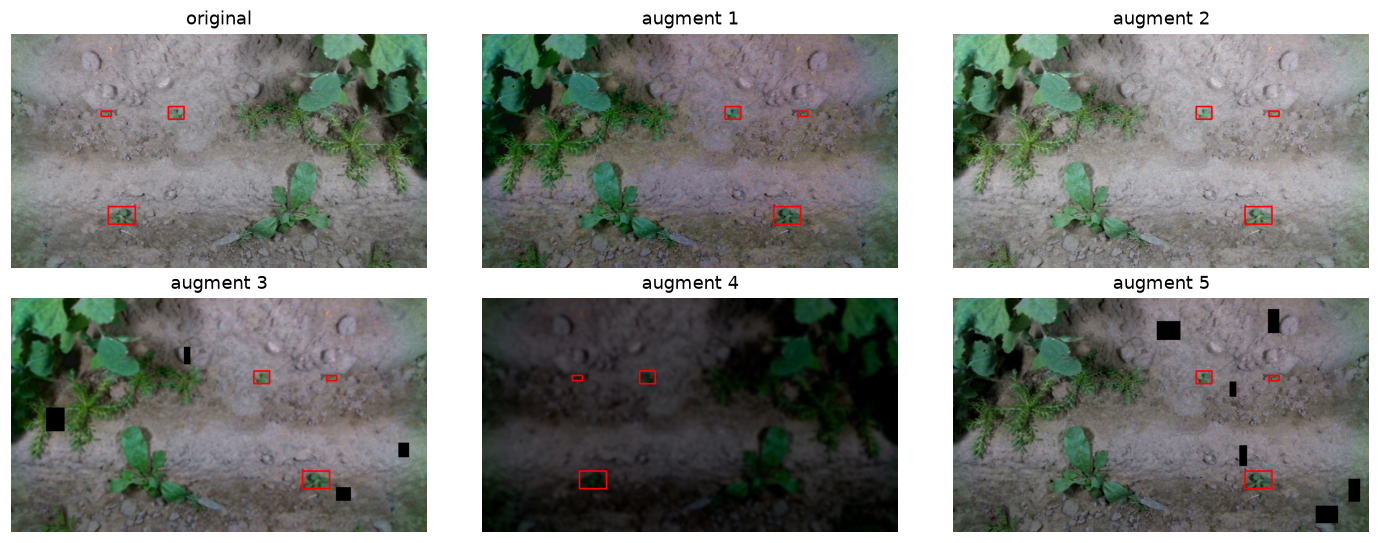

In [7]:
from weedvision import augment as AU
import cv2, random
random.seed(1); np.random.seed(1)
f = sorted((ROOT/"sample_data").glob("sudars_test_1*.jpg"))[0]; img = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)
lab = np.loadtxt(ROOT/"data/processed/sudars_weed/labels/test"/(f.stem.replace("sudars_test_","")+".txt"), ndmin=2); h, w = img.shape[:2]
boxes = [((x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h) for _, x, y, bw, bh in lab]
aug = AU.build(); fig, ax = plt.subplots(2, 3, figsize=(13, 5))
for a_, k in zip(ax.ravel(), range(6)):
    im, bb, _ = (img, boxes, None) if k == 0 else AU.apply(aug, img, boxes, [0]*len(boxes))
    im = im.copy()
    for x1, y1, x2, y2 in bb: cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 3)
    a_.imshow(im); a_.axis("off"); a_.set_title("original" if k == 0 else f"augment {k}")
plt.tight_layout(); plt.show()

**Leitura:** exemplos do pipeline próprio (iluminação, gama, desfoque, neblina como aproximação de poeira, matiz, oclusão retangular, ruído). Ele é testado quanto à validade das caixas, mas **não foi usado nos pesos reportados** e seu ganho **não foi medido**.